# Batch size experiment - mfcc

In [ ]:
# DATA_DIR = DATA_DIR

TRAIN_DIR = DATA_DIR / 'train'
VALID_DIR = DATA_DIR / 'valid'
TEST_DIR = DATA_DIR / 'test'
NOISE_DIR = DATA_DIR / '_background_noise_'

print("Train:", len(list(TRAIN_DIR.rglob("*.wav"))))
print("Valid:", len(list(VALID_DIR.rglob("*.wav"))))

Train: 51486
Valid: 6828


In [ ]:
from pathlib import Path
import torch
import numpy as np
import random
import pandas as pd
import gc
import itertools

from data.utils import get_datasets, precompute_features
from data.dataset import CachedDataset
from data.transforms import FeatureConfig

from models.train import train, predict
from models.evaluate import evaluate
from models.transformer import Transformer
from models.cnn_transformer import CNNTransformer
from models.utils import set_seed

from plots import (
    plot_f1_training_curves,
    build_summary_df,
    plot_summary_table,
    plot_metrics_comparison,
    plot_f1_comparison,
    plot_confusion_matrix
)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print("Using device:", device)

Using device: cuda


In [ ]:
SEEDS = [0, 1, 2]
EPOCHS = 30
REPR = "mfcc"
DROPOUT = 0.1
LR = 3e-4

In [ ]:
train_ds, valid_ds, test_ds = get_datasets(
    data_format=REPR,
    train_path=TRAIN_DIR,
    valid_path=VALID_DIR,
    test_path=TEST_DIR,
)

In [ ]:
CACHE_DIR = Path("/kaggle/working/cache_batch_size_mfcc")

precompute_features(train_ds, CACHE_DIR / "train")
precompute_features(valid_ds, CACHE_DIR / "valid")
precompute_features(test_ds, CACHE_DIR / "test")

train_ds_cached = CachedDataset(CACHE_DIR / "train")
valid_ds_cached = CachedDataset(CACHE_DIR / "valid")
test_ds_cached = CachedDataset(CACHE_DIR / "test")

  0%|          | 0/51486 [00:00<?, ?it/s]

Saved 51486 samples to /kaggle/working/cache_batch_size_mfcc/train


  0%|          | 0/6828 [00:00<?, ?it/s]

Saved 6828 samples to /kaggle/working/cache_batch_size_mfcc/valid


  0%|          | 0/6865 [00:00<?, ?it/s]

Saved 6865 samples to /kaggle/working/cache_batch_size_mfcc/test


In [ ]:
def cnn_transformer_factory(repr_name="mel", dropout=0.1):
    n_features = 40 if repr_name == "mfcc" else 64

    return CNNTransformer(
        n_features=n_features,
        n_timesteps=101,
        num_classes=12,
        base_channels=32,
        d_model=128,
        nhead=4,
        num_layers=4,
        dropout=dropout,
        pooling="mean",
    )

In [ ]:
BATCH_SIZES = [32, 64, 128, 256]

In [ ]:
BATCH_SIZE_MFCC_SAVE_PATH = "/kaggle/working/batch_size_experiment_mfcc.csv"

def batch_size_experiment_mfcc(
    batch_size_values,
    seeds=[0, 1, 2],
    epochs=30,
    lr=3e-4,
    dropout=0.1,
):
    results = {}
    rows = []

    for batch_size in batch_size_values:
        results[batch_size] = {}

        for seed in seeds:
            print(f"\nBatch size={batch_size} | seed={seed}")

            set_seed(seed)

            model = cnn_transformer_factory(
                repr_name=REPR,
                dropout=dropout,
            ).to(device)

            model, history = train(
                model,
                train_ds_cached,
                valid_ds_cached,
                epochs=epochs,
                batch_size=batch_size,
                lr=lr,
                device=device,
            )

            preds_test, labels_test = predict(
                model,
                test_ds_cached,
                device=device,
                batch_size=batch_size,
            )

            test_result = evaluate(
                preds_test,
                labels_test,
                print_report=False,
            )

            results[batch_size][seed] = {
                "history": history,
                "valid_acc": max(history["valid_acc"]),
                "valid_macro_f1": max(history["valid_f1"]),
                "test_acc": test_result["acc"],
                "test_macro_f1": test_result["macro_f1"],
                "test_weighted_f1": test_result["weighted_f1"],
                "test_cm": test_result["cm"],
            }

            rows.append({
                "batch_size": batch_size,
                "seed": seed,
                "lr": lr,
                "dropout": dropout,
                "best_valid_acc": max(history["valid_acc"]),
                "best_valid_macro_f1": max(history["valid_f1"]),
                "test_acc": test_result["acc"],
                "test_macro_f1": test_result["macro_f1"],
                "test_weighted_f1": test_result["weighted_f1"],
            })

            pd.DataFrame(rows).to_csv(BATCH_SIZE_MFCC_SAVE_PATH, index=False)

            del model
            torch.cuda.empty_cache()
            gc.collect()

    return results, pd.DataFrame(rows)

In [ ]:
batch_size_mfcc_results, df_batch_size_mfcc = batch_size_experiment_mfcc(
    batch_size_values=BATCH_SIZES,
    seeds=SEEDS,
    epochs=EPOCHS,
    lr=LR,
    dropout=DROPOUT,
)

df_batch_size_mfcc.sort_values("test_macro_f1", ascending=False)


Batch size=32 | seed=0
Epoch 1/30 | Train Loss: 0.5629 | Valid Loss: 0.2968 | Valid Acc: 0.9050 | Valid Macro F1: 0.8537
Epoch 2/30 | Train Loss: 0.2118 | Valid Loss: 0.2714 | Valid Acc: 0.9149 | Valid Macro F1: 0.8680
Epoch 3/30 | Train Loss: 0.1595 | Valid Loss: 0.2289 | Valid Acc: 0.9288 | Valid Macro F1: 0.8920
Epoch 4/30 | Train Loss: 0.1317 | Valid Loss: 0.1761 | Valid Acc: 0.9473 | Valid Macro F1: 0.9210
Epoch 5/30 | Train Loss: 0.1136 | Valid Loss: 0.1829 | Valid Acc: 0.9439 | Valid Macro F1: 0.9160
Epoch 6/30 | Train Loss: 0.0968 | Valid Loss: 0.1989 | Valid Acc: 0.9392 | Valid Macro F1: 0.9103
Epoch 7/30 | Train Loss: 0.0881 | Valid Loss: 0.1861 | Valid Acc: 0.9493 | Valid Macro F1: 0.9243
Epoch 8/30 | Train Loss: 0.0765 | Valid Loss: 0.1830 | Valid Acc: 0.9486 | Valid Macro F1: 0.9185
Epoch 9/30 | Train Loss: 0.0717 | Valid Loss: 0.1544 | Valid Acc: 0.9572 | Valid Macro F1: 0.9358
Epoch 10/30 | Train Loss: 0.0595 | Valid Loss: 0.1552 | Valid Acc: 0.9578 | Valid Macro F1: 0.

,batch_size,seed,lr,dropout,best_valid_acc,best_valid_macro_f1,test_acc,test_macro_f1,test_weighted_f1
1,32,1,0.0003,0.1,0.965729,0.948068,0.971595,0.959488,0.971398
2,32,2,0.0003,0.1,0.965436,0.950084,0.970867,0.958319,0.970683
5,64,2,0.0003,0.1,0.961482,0.943410,0.969556,0.956615,0.969474
4,64,1,0.0003,0.1,0.962068,0.943510,0.969556,0.956202,0.969413
0,32,0,0.0003,0.1,0.963679,0.944961,0.968973,0.953599,0.968809
3,64,0,0.0003,0.1,0.961629,0.943246,0.967808,0.953499,0.967628
8,128,2,0.0003,0.1,0.963093,0.944453,0.968827,0.951388,0.968714
7,128,1,0.0003,0.1,0.959725,0.941812,0.966205,0.949245,0.966129
6,128,0,0.0003,0.1,0.963093,0.944146,0.966205,0.946093,0.966086
10,256,1,0.0003,0.1,0.959285,0.940937,0.962564,0.942490,0.962492


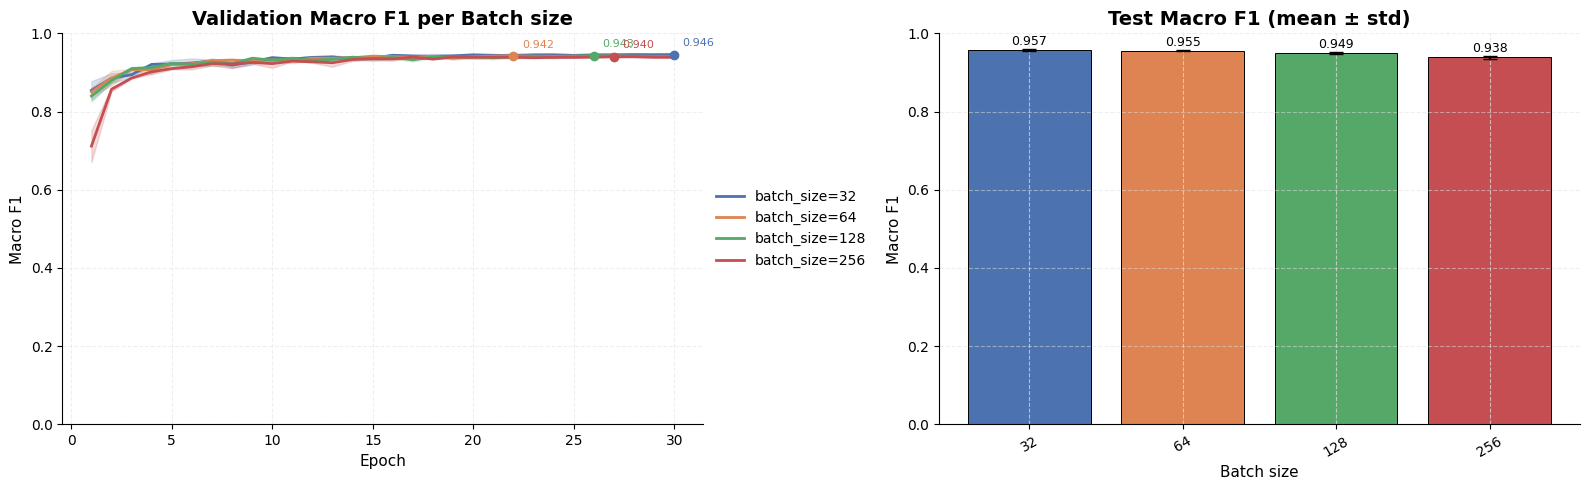

In [ ]:
plot_f1_comparison(
    batch_size_mfcc_results,
    param_name="Batch size",
    param_name_short="batch_size"
)